# ANÁLISE P3 | _The Numbers Domestic Box Office Dataset_
___
Análises voltadas para responder à pergunta P3.
___

### 0 | Importações
___

In [8]:
# Manipulação de dados:
import pandas as pd
import numpy as np             

# Visualização de dados:
import plotly.express as px 
import plotly.io as pio

pio.renderers.default='png'

In [9]:
df = pd.read_csv('../data/processed/tabela_tratada.csv') # Importando o dataset

### P3 | Explorando correlações entre dados de filmes
___


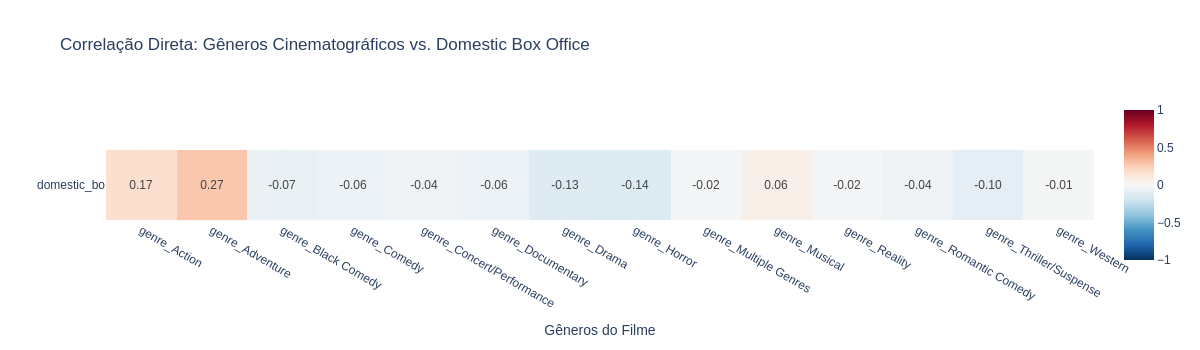

In [10]:
# Transforma o gênero em colunas binárias (One-Hot Encoding) se a coluna existir
if 'genre' in df.columns:
    df_encoded = pd.get_dummies(df, columns=['genre'], drop_first=False, dtype=int)
else:
    df_encoded = df.copy()

# Seleciona apenas as colunas numéricas globais
df_numerico = df_encoded.select_dtypes(include=[np.number])

# Calcula a matriz de correlação completa
matriz_corr = df_numerico.corr()

# Filtra a matriz para manter APENAS 'domestic_bo' e as colunas iniciadas com 'genre_'
colunas_genero = [col for col in matriz_corr.columns if col.startswith('genre_')]

if 'domestic_bo' in matriz_corr.columns and colunas_genero:
    # Cria uma matriz reduzida contendo apenas domestic_bo x gêneros
    matriz_focada = matriz_corr.loc[['domestic_bo'], colunas_genero]

    # Gera o Heatmap focado com Plotly
    fig = px.imshow(
        matriz_focada,
        text_auto='.2f',
        color_continuous_scale='RdBu_r',
        zmin=-1, zmax=1,
        title='Correlação Direta: Gêneros Cinematográficos vs. Domestic Box Office'
    )

    fig.update_layout(
        width=1200,
        height=350,  # Altura reduzida já que é uma matriz de uma linha só
        template='plotly_white',
        xaxis_title='Gêneros do Filme',
        yaxis_title=''
    )

    fig.show()
else:
    print("Aviso: As colunas 'domestic_bo' ou os gêneros codificados não foram encontrados no DataFrame.")

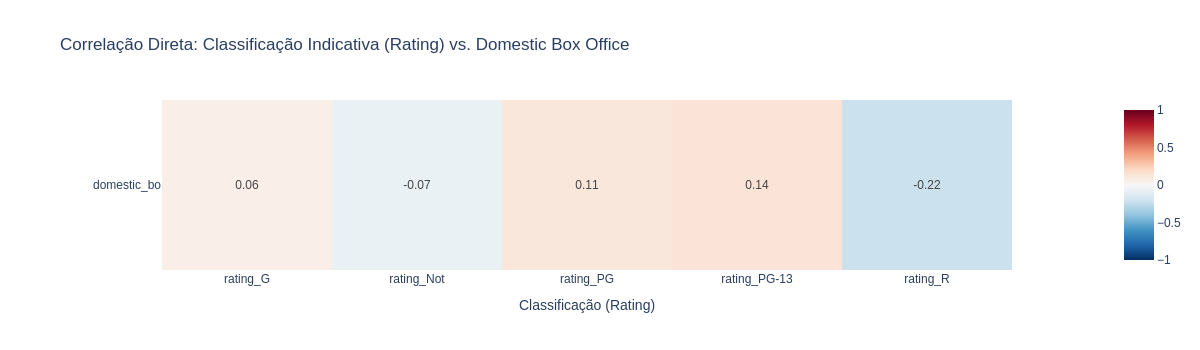

In [12]:
candidatos_rating = ['rating', 'mpaa_rating', 'classificacao', 'content_rating']
col_rating = next((c for c in candidatos_rating if c in df.columns), None)

if col_rating:
    df_encoded = pd.get_dummies(df, columns=[col_rating], drop_first=False, dtype=int)
    prefixo_rating = f"{col_rating}_"
else:
    df_encoded = df.copy()
    prefixo_rating = 'rating_'

# Seleciona colunas numéricas e calcula a correlação
df_numerico = df_encoded.select_dtypes(include=[np.number])
matriz_corr = df_numerico.corr()

# Filtra apenas 'domestic_bo' e as colunas codificadas de rating
colunas_rating = [col for col in matriz_corr.columns if col.startswith(prefixo_rating)]

if 'domestic_bo' in matriz_corr.columns and colunas_rating:
    matriz_focada_rating = matriz_corr.loc[['domestic_bo'], colunas_rating]

    fig = px.imshow(
        matriz_focada_rating,
        text_auto='.2f',
        color_continuous_scale='RdBu_r',
        zmin=-1,
        zmax=1,
        title='Correlação Direta: Classificação Indicativa (Rating) vs. Domestic Box Office'
    )

    fig.update_layout(
        width=1200,
        height=350,
        template='plotly_white',
        xaxis_title='Classificação (Rating)',
        yaxis_title=''
    )

    fig.show()
else:
    print("Aviso: Coluna 'domestic_bo' ou colunas de rating não encontradas no DataFrame.")

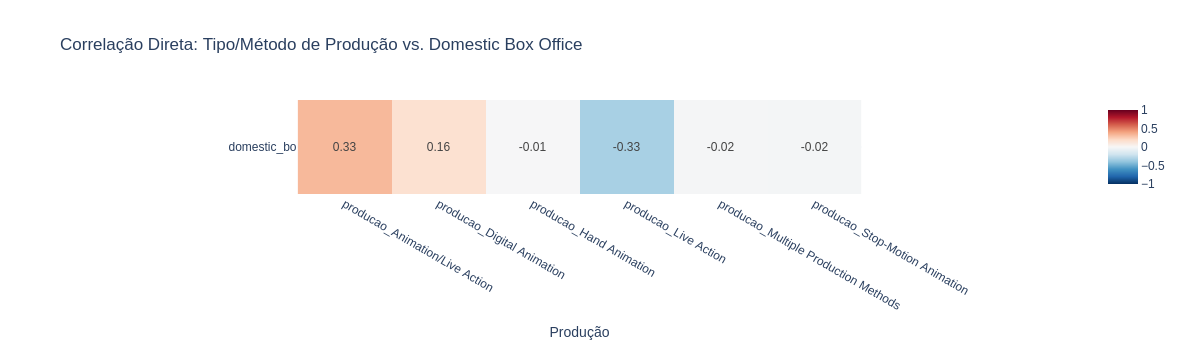

In [13]:
candidatos_producao = [
    'production_method', 'producao', 'production',
    'creative_type', 'tipo_producao', 'source'
]
col_producao = next((c for c in candidatos_producao if c in df.columns), None)

if col_producao:
    df_encoded = pd.get_dummies(df, columns=[col_producao], drop_first=False, dtype=int)
    prefixo_producao = f"{col_producao}_"
else:
    df_encoded = df.copy()
    prefixo_producao = 'production_'

# Seleciona colunas numéricas e calcula a correlação
df_numerico = df_encoded.select_dtypes(include=[np.number])
matriz_corr = df_numerico.corr()

# Filtra apenas 'domestic_bo' e as colunas codificadas de produção
colunas_producao = [col for col in matriz_corr.columns if col.startswith(prefixo_producao)]

if 'domestic_bo' in matriz_corr.columns and colunas_producao:
    matriz_focada_producao = matriz_corr.loc[['domestic_bo'], colunas_producao]

    fig = px.imshow(
        matriz_focada_producao,
        text_auto='.2f',
        color_continuous_scale='RdBu_r',
        zmin=-1,
        zmax=1,
        title='Correlação Direta: Tipo/Método de Produção vs. Domestic Box Office'
    )

    fig.update_layout(
        width=1200,
        height=350,
        template='plotly_white',
        xaxis_title='Produção',
        yaxis_title=''
    )

    fig.show()
else:
    print("Aviso: Coluna 'domestic_bo' ou colunas de produção não encontradas no DataFrame.")